# Notebook 1: LSIS-AFS Spreading Codes

**LunaLink Reference Implementation — Pedagogical Notebook Series**

This notebook teaches the spreading code layer of the
[LunaNet](https://www.nasa.gov/humans-in-space/lunanet-empowering-artemis-with-communications-and-navigation-interoperability/) Signal-In-Space
Augmented Forward Signal (LSIS-AFS). By the end, you will understand *how* and
*why* each code family is constructed, and be able to generate and validate all
210 PRN codes yourself.

> **Spec reference:** LSIS-AFS Volume A, V1.0, §2.3.5 — *Spreading Codes Characteristics*
> ([CCSDS](https://ccsds.org/), 29 January 2025)

### What you will learn

| Section | Topic | Spec section |
|---------|-------|-------------|
| 1 | Why spreading codes? (CDMA primer) | §2.3 overview |
| 2 | Gold codes — LFSR construction | §2.3.5.3.1 (LSIS-221), Appendix C |
| 3 | Weil codes — Legendre sequences and cyclic shifts | §2.3.5.3.2 (LSIS-222), Appendix D |
| 4 | Tertiary codes — short Weil sequences | §2.3.5.3.2 (LSIS-224), Appendix E |
| 5 | Secondary codes — 4-chip epoch markers | §2.3.5.3.2 (LSIS-223), Table 10 |
| 6 | Tiered code assembly — putting it all together | §2.3.5.2 |
| 7 | Correlation properties — why these codes work | — |
| 8 | Validation against Annex 3 reference data | Annex 3 |

### Prerequisites

```
pip install lunalink matplotlib
```

### Background reading

If any concept in this notebook is new to you, these references provide deeper context:

- **Spread spectrum & CDMA:** Haykin, *Communication Systems* (Wiley, 4th ed.), Ch. 9.
  See also [Scholtz, "The Spread Spectrum Concept" (IEEE Trans. Comm., 1977)](https://doi.org/10.1109/TCOM.1977.1093907).
- **GNSS signal design:** Kaplan & Hegarty,
  [*Understanding GPS/GNSS: Principles and Applications*](https://openlibrary.org/isbn/9781630810580)
  (Artech House, 3rd ed., 2017), Ch. 4 — the standard graduate-level GNSS textbook.
- **Gold codes:** R. Gold, ["Optimal binary sequences for spread spectrum multiplexing" (IEEE Trans. IT, 1967)](https://doi.org/10.1109/TIT.1967.1054048) — the original paper.
- **Weil codes for navigation:** J. Rushanan, ["Weil Sequences: A Family of Binary Sequences with Good Correlation Properties" (IEEE ISIT, 2006)](https://doi.org/10.1109/ISIT.2006.261556).
  See also Soualle et al., "Spreading Code Selection Criteria for the Future Galileo L1 OS Signal" (ION GNSS, 2005).
- **LFSRs & m-sequences:** Golomb, *Shift Register Sequences* (Aegean Park Press, rev. ed.) — the
  definitive treatment of LFSR theory.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from lunalink.afs import (
    # Code generators
    prn_code,           # Gold code (2046 chips)
    weil10230_code,     # Weil primary code (10230 chips)
    weil1500_code,      # Weil tertiary code (1500 chips)
    matched_code_epoch, # Tiered code for one 2ms epoch
    default_matched_assignment,
    # Constants
    EPOCHS_PER_FRAME,
    SECONDARY_CODE_LENGTH,
    TERTIARY_CODE_LENGTH,
)
from lunalink.afs._afs import (
    GOLD_CHIP_LENGTH,
    WEIL_10230_CHIP_LENGTH,
    WEIL_1500_CHIP_LENGTH,
    PRN_COUNT,
)

# Plotting defaults for publication-quality figures
plt.rcParams.update({
    "figure.figsize": (10, 4),
    "figure.dpi": 120,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

print(f"LunaLink loaded — {PRN_COUNT} PRNs available")
print(f"  Gold code length:    {GOLD_CHIP_LENGTH:>6,} chips")
print(f"  Weil primary length: {WEIL_10230_CHIP_LENGTH:>6,} chips")
print(f"  Weil tertiary length:{WEIL_1500_CHIP_LENGTH:>6,} chips")
print(f"  Secondary code length:    {SECONDARY_CODE_LENGTH} chips")
print(f"  Epochs per frame:    {EPOCHS_PER_FRAME:>6,} (12 s at 2 ms/epoch)")

LunaLink loaded — 210 PRNs available
  Gold code length:     2,046 chips
  Weil primary length: 10,230 chips
  Weil tertiary length: 1,500 chips
  Secondary code length:    4 chips
  Epochs per frame:     6,000 (12 s at 2 ms/epoch)


---

## 1. Why spreading codes?

Navigation satellites share the same radio frequency using
[**Code Division Multiple Access (CDMA)**](https://en.wikipedia.org/wiki/Code-division_multiple_access).
Each satellite transmits a unique
[pseudo-random noise (PRN)](https://en.wikipedia.org/wiki/Pseudorandom_noise) code — a
deterministic binary sequence that *looks* random — at a much higher rate than the
navigation data it carries. Each binary element of the PRN sequence is called a
[**chip**](https://en.wikipedia.org/wiki/Chip_%28CDMA%29), and the transmission rate is
the **chip rate** (chips per second), as distinct from the data bit rate.

The receiver multiplies the incoming signal by a locally generated replica of the
code — if the codes match, the signal is
[*despread*](https://en.wikipedia.org/wiki/Spread_spectrum#Despreading) and the data
emerges; signals from other satellites appear as low-level noise.

This works because good spreading codes have two properties:

1. **Sharp [autocorrelation](https://en.wikipedia.org/wiki/Autocorrelation)** — the
   code correlates strongly only when perfectly aligned with itself, giving precise
   time-of-arrival measurements.
2. **Low [cross-correlation](https://en.wikipedia.org/wiki/Cross-correlation)** —
   different codes produce near-zero correlation, so multiple satellites can transmit
   simultaneously without interfering.

LSIS-AFS uses a **three-tier** code structure (similar to
[GPS L1C](https://en.wikipedia.org/wiki/GPS_signals#L1C), adapted for cislunar distances):

```
AFS-I (data channel):  Gold code (2,046 chips)  ← one code period = one data symbol
AFS-Q (pilot channel): Weil primary (10,230 chips)
                        ⊕ secondary (4 chips)
                        ⊕ tertiary (1,500 chips)  ← "matched code"
```

The I-channel carries navigation data modulated by a short Gold code (the **data channel**).
The Q-channel is an unmodulated **[pilot channel](https://en.wikipedia.org/wiki/Pilot_signal)** —
it uses longer Weil codes for better acquisition sensitivity because the receiver can
integrate over many more chips without data bit transitions corrupting the correlation.

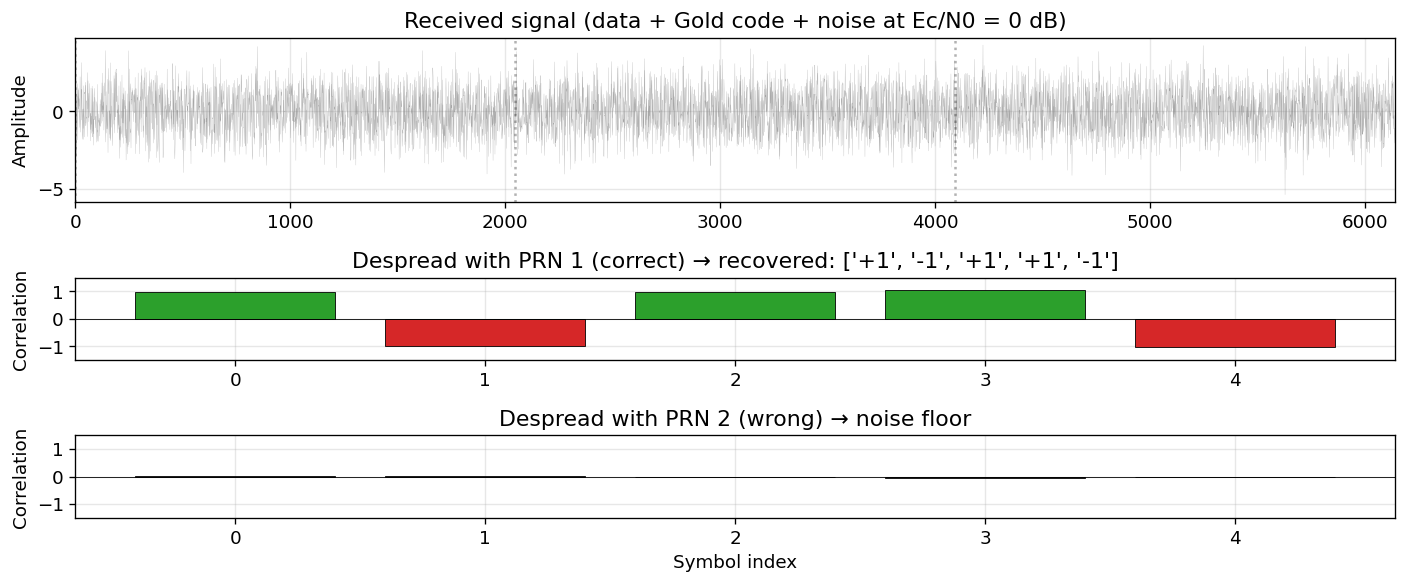

Original data:     [1, -1, 1, 1, -1]
Recovered (PRN 1): ['+1', '-1', '+1', '+1', '-1']
Wrong key (PRN 2): ['+0.031', '+0.004', '-0.028', '-0.043', '-0.002']  ← noise


In [2]:
# --- CDMA despreading demo: the "aha moment" ---
# Show that multiplying by the right code recovers data; the wrong code gives noise.

rng = np.random.default_rng(42)
code_a = prn_code(1)  # "our" satellite's Gold code
code_b = prn_code(2)  # a different satellite

# Transmit 5 data symbols: [+1, -1, +1, +1, -1]
data_symbols = np.array([1, -1, 1, 1, -1])
n_symbols = len(data_symbols)

# Spread: each symbol is XOR-ed with the full code (bipolar: 0→+1, 1→-1)
code_bipolar = 1.0 - 2.0 * code_a.astype(np.float64)
tx_signal = np.concatenate([sym * code_bipolar for sym in data_symbols])

# Add noise (Ec/N0 = 0 dB — quite harsh)
noise = rng.normal(0, 1.0, len(tx_signal))
rx_signal = tx_signal + noise

# Despread with the CORRECT code → data pops out
despread_correct = np.array([
    np.dot(rx_signal[i * len(code_a):(i + 1) * len(code_a)], code_bipolar) / len(code_a)
    for i in range(n_symbols)
])

# Despread with the WRONG code → just noise
code_b_bipolar = 1.0 - 2.0 * code_b.astype(np.float64)
despread_wrong = np.array([
    np.dot(rx_signal[i * len(code_a):(i + 1) * len(code_a)], code_b_bipolar) / len(code_a)
    for i in range(n_symbols)
])

fig, axes = plt.subplots(3, 1, figsize=(12, 5), gridspec_kw={"height_ratios": [2, 1, 1]})

# Raw received signal (looks like noise)
axes[0].plot(rx_signal[:3 * len(code_a)], linewidth=0.15, color="gray", alpha=0.7)
axes[0].set_title("Received signal (data + Gold code + noise at Ec/N0 = 0 dB)")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, 3 * len(code_a))
for i in range(3):
    axes[0].axvline(i * len(code_a), color="k", linestyle=":", alpha=0.3)

# Despread with correct code
colors = ["C2" if v > 0 else "C3" for v in despread_correct]
axes[1].bar(range(n_symbols), despread_correct, color=colors, edgecolor="k", linewidth=0.5)
axes[1].axhline(0, color="k", linewidth=0.5)
axes[1].set_title(f"Despread with PRN 1 (correct) → recovered: {['+1' if v > 0 else '-1' for v in despread_correct]}")
axes[1].set_ylabel("Correlation")
axes[1].set_ylim(-1.5, 1.5)

# Despread with wrong code
axes[2].bar(range(n_symbols), despread_wrong, color="gray", edgecolor="k", linewidth=0.5)
axes[2].axhline(0, color="k", linewidth=0.5)
axes[2].set_title(f"Despread with PRN 2 (wrong) → noise floor")
axes[2].set_ylabel("Correlation")
axes[2].set_ylim(-1.5, 1.5)
axes[2].set_xlabel("Symbol index")

fig.tight_layout()
plt.show()

print(f"Original data:     {data_symbols.tolist()}")
print(f"Recovered (PRN 1): {['+1' if v > 0 else '-1' for v in despread_correct]}")
print(f"Wrong key (PRN 2): {[f'{v:+.3f}' for v in despread_wrong]}  ← noise")

---

## 2. Gold codes (AFS-I)

> **Spec:** §2.3.5.3.1 (LSIS-221), Appendix C — *Gold Code Generation*

[Gold codes](https://en.wikipedia.org/wiki/Gold_code) are the workhorse of
[GNSS](https://en.wikipedia.org/wiki/Satellite_navigation): GPS
[L1 C/A](https://en.wikipedia.org/wiki/GPS_signals#Coarse/acquisition_code) uses them,
and so does LSIS-AFS for the I-channel. A Gold code is the chip-by-chip
[XOR](https://en.wikipedia.org/wiki/Exclusive_or) of two
[maximum-length sequences (m-sequences)](https://en.wikipedia.org/wiki/Maximum_length_sequence)
from [Linear Feedback Shift Registers (LFSRs)](https://en.wikipedia.org/wiki/Linear-feedback_shift_register).

**Construction:**

Two 11-bit LFSRs produce m-sequences of length $2^{11} - 1 = 2047$ chips. Per
LSIS-221, the Gold code is **short-cycled** (truncated) to **2,046** chips by
reinitialising the LFSRs every 2,046 chips.

| LFSR | [Generator polynomial](https://en.wikipedia.org/wiki/Primitive_polynomial_%28field_theory%29) | Taps |
|------|---------------------|------|
| G1 | $x^{11} + x^2 + 1$ | [11, 2] |
| G2 | $x^{11} + x^8 + x^5 + x^2 + 1$ | [11, 8, 5, 2] |

The figure below (from the LSIS spec, Appendix C) shows the two LFSRs and how
their outputs are combined. Each PRN gets a unique code by applying a different
**delay** $D_k$ to G2 before XOR-ing with G1:

$$\text{Gold}[n] = \text{G1}[n] \oplus \text{G2}[n + \tau_{\text{PRN}}] \pmod{2046}$$

![Figure C-1: Data Channel (AFS-I) Gold code generator.
*(Source: LSIS V1.0, Appendix C, Figure C-1)*](figures/fig_c1_gold_lfsr.png)

Let's generate and inspect a Gold code:

In [3]:
# Generate Gold codes for PRN 1 and PRN 2
gold_1 = prn_code(1)
gold_3 = prn_code(3)

print(f"Gold code PRN 1:  length = {len(gold_1)}, ones = {gold_1.sum()}, zeros = {(1 - gold_1).sum()}")
print(f"Gold code PRN 3:  length = {len(gold_3)}, ones = {gold_3.sum()}, zeros = {(1 - gold_3).sum()}\n")

print(f"First 30 chips of PRN 1: {gold_1[:30].tolist()}")
print(f"First 30 chips of PRN 3: {gold_3[:30].tolist()}\n")

# A good PRN code is roughly balanced: ~50% ones, ~50% zeros
balance_1 = gold_1.sum() / len(gold_1)
balance_3 = gold_3.sum() / len(gold_3)
print(f"PRN 1 balance: {balance_1:.3f} (ideal = 0.500)")
print(f"PRN 3 balance: {balance_3:.4f} (ideal = 0.500)")

Gold code PRN 1:  length = 2046, ones = 992, zeros = 1054
Gold code PRN 3:  length = 2046, ones = 1056, zeros = 990

First 30 chips of PRN 1: [0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1]
First 30 chips of PRN 3: [0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1]

PRN 1 balance: 0.485 (ideal = 0.500)
PRN 3 balance: 0.5161 (ideal = 0.500)


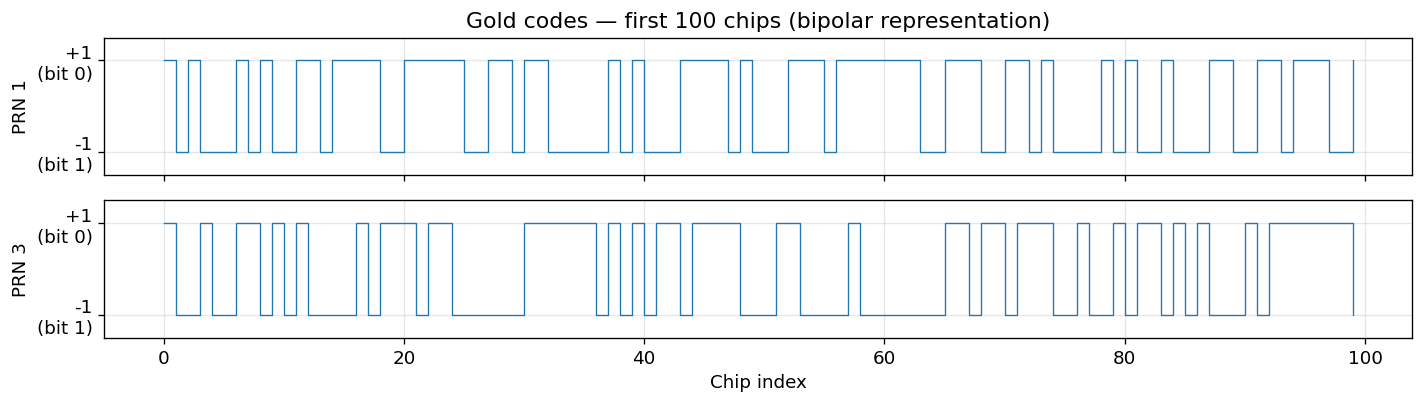

In [4]:
# Visualise the first 100 chips — the code looks random, but it's deterministic
fig, axes = plt.subplots(2, 1, figsize=(12, 3.5), sharex=True)

for ax, code, prn in zip(axes, [gold_1, gold_3], [1, 3]):
    # Convert 0/1 → ±1 (bipolar) for visual clarity
    bipolar = np.where(code[:100] == 0, 1.0, -1.0)
    ax.step(range(100), bipolar, where="post", linewidth=0.8)
    ax.set_ylabel(f"PRN {prn}")
    ax.set_ylim(-1.5, 1.5)
    ax.set_yticks([-1, 1])
    ax.set_yticklabels(["-1\n(bit 1)", "+1\n(bit 0)"])

axes[1].set_xlabel("Chip index")
axes[0].set_title("Gold codes — first 100 chips (bipolar representation)")
fig.tight_layout()
plt.show()

### Why 2,046 chips?

GPS L1 C/A Gold codes are 1,023 chips long (from 10-bit LFSRs: $2^{10} - 1$).
LSIS-AFS uses 11-bit LFSRs ($2^{11} - 1 = 2047$), short-cycled to **2,046** chips.
The longer code gives approximately **3 dB more
[processing gain](https://en.wikipedia.org/wiki/Process_gain)** — the ratio of
chip rate to data rate, which determines how far below the noise floor a signal
can be recovered. This extra gain is important for
[cislunar](https://en.wikipedia.org/wiki/Cislunar_space) distances where signals
are much weaker than terrestrial GNSS.

The Gold code is transmitted on **AFS-I** at a chip rate of **1.023 Mchip/s** (same
as GPS L1 C/A). One complete code period = $2046 / 1.023 \times 10^6 = 2$ ms,
which is also the duration of one data symbol (500 symbols/s, per Table 7).

---

## 3. Weil codes (AFS-Q primary)

> **Spec:** §2.3.5.3.2 (LSIS-222), Appendix D — *Weil Primary Code Generation*

The Q-channel (pilot, no data) uses **Weil codes** — a code family named after
mathematician [André Weil](https://en.wikipedia.org/wiki/Andr%C3%A9_Weil), derived
from the [Legendre symbol](https://en.wikipedia.org/wiki/Legendre_symbol) in
[number theory](https://en.wikipedia.org/wiki/Quadratic_residue). Weil codes offer
better correlation properties than Gold codes at longer lengths
(see [Rushanan, 2006](https://doi.org/10.1109/ISIT.2006.261556)), which is why
they're chosen for the pilot channel where the receiver does its heavy correlation
lifting. The same construction is used by GPS L1C (IS-GPS-800J).

**Construction in three steps:**

1. **[Legendre sequence](https://en.wikipedia.org/wiki/Legendre_symbol#Sequences_and_arrays_derived_from_the_Legendre_symbol)**:
   For a prime $p = 10223$, compute the Legendre symbol
   $\left(\frac{n}{p}\right)$ for $n = 0, 1, \ldots, p-1$.
   Per the spec (Appendix D):
   - $L(0) = 0$
   - $L(t) = 1$ if $t$ is a [quadratic residue](https://en.wikipedia.org/wiki/Quadratic_residue) mod $p$
     (i.e., $\exists\, x : x^2 \equiv t \pmod{p}$)
   - $L(t) = 0$ if $t$ is a non-residue

   This gives a $\{0, 1\}$ sequence of length 10,223 with 5,111 ones and 5,112 zeros.

2. **Cyclic shift**: Each PRN gets a unique shift index $k$ (from Appendix D).
   The Weil code is:

$$W[n] = L[n] \oplus L[(n + k) \bmod p]$$

3. **Expansion**: Insert a fixed 7-chip expansion sequence $[0, 1, 1, 0, 1, 0, 0]$ at
   a PRN-specific insertion point $p_{\text{ins}}$ (also from Appendix D), extending
   the code from 10,223 to **10,230** chips. The expansion sequence is always the same for all 210 PRNs; what varies is the insertion index $p$ (from Tables D-2 through D-6), which determines where in the 10,223-chip Weil code those 7 chips get spliced in.

The final length of 10,230 = $5 \times 2046$ is exactly 5 Gold code periods.
This clean integer relationship keeps the code boundaries aligned across the
I and Q channels — a crucial property for receiver design.

**Perfect balance:** Every Weil primary code has exactly 5,115 ones and 5,115 zeros —
all 210 of them, no exceptions. This is a consequence of the construction: the
pre-expansion Weil code (10,223 chips) has 5,112 ones and 5,111 zeros (one more
one than zero). The 7-chip expansion $[0,1,1,0,1,0,0]$ adds 3 ones and 4 zeros,
restoring exact 50/50 balance at 10,230 chips. Gold codes, by contrast, are only
*approximately* balanced.

In [5]:
# Generate Weil primary codes
weil_1 = weil10230_code(1)
weil_3 = weil10230_code(3)

print(f"Weil primary PRN 1: length = {len(weil_1):,}, ones = {weil_1.sum():,}")
print(f"Weil primary PRN 3: length = {len(weil_3):,}, ones = {weil_3.sum():,}\n")
print(f"Note: 10,230 = 5 × {GOLD_CHIP_LENGTH} (Gold code length)")
print(f"      → one Weil period spans exactly 5 Gold code periods\n")

# Balance check
balance = weil_1.sum() / len(weil_1)
print(f"PRN 1 balance: {balance:.4f} (ideal = 0.5000)")

balance = weil_3.sum() / len(weil_3)
print(f"PRN 3 balance: {balance:.4f} (ideal = 0.5000)")

Weil primary PRN 1: length = 10,230, ones = 5,115
Weil primary PRN 3: length = 10,230, ones = 5,115

Note: 10,230 = 5 × 2046 (Gold code length)
      → one Weil period spans exactly 5 Gold code periods

PRN 1 balance: 0.5000 (ideal = 0.5000)
PRN 3 balance: 0.5000 (ideal = 0.5000)


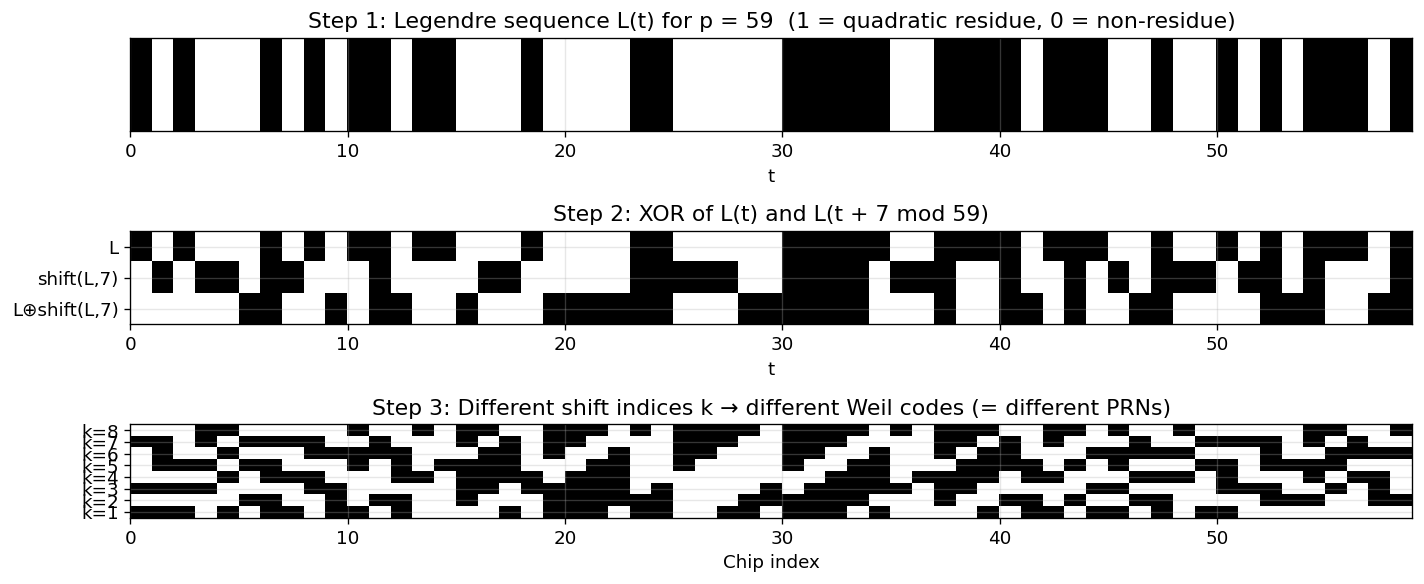

Each shift index k produces a unique code from the same Legendre sequence.
LSIS-AFS uses p=10223 (primary) and p=1499 (tertiary), with k from Appendix D/E.


In [6]:
# --- Weil code construction walkthrough ---
# Build a Weil code from scratch to demystify the Legendre sequence

# Step 1: Compute the Legendre sequence for a SMALL prime (p=59) to visualise
# (The real code uses p=10223, but we'll show the structure on a tractable size)
# Convention per LSIS Appendix D: L(t)=1 if t is a quadratic residue, L(t)=0 otherwise
p_demo = 59
qr = set()
for x in range(1, p_demo):
    qr.add((x * x) % p_demo)

legendre_demo = np.zeros(p_demo, dtype=np.uint8)
legendre_demo[0] = 0  # L(0) = 0 by definition
for t in range(1, p_demo):
    legendre_demo[t] = 1 if t in qr else 0  # 1 = residue, 0 = non-residue

fig, axes = plt.subplots(3, 1, figsize=(12, 5))

# The raw Legendre sequence — notice the structure (NOT random!)
ax = axes[0]
ax.imshow(legendre_demo.reshape(1, -1), cmap="binary_r", aspect="auto",
          extent=[0, p_demo, -0.5, 0.5], interpolation="nearest")
ax.set_title(f"Step 1: Legendre sequence L(t) for p = {p_demo}  "
             f"(1 = quadratic residue, 0 = non-residue)")
ax.set_xlabel("t")
ax.set_yticks([])

# Step 2: Cyclic shift and XOR — make a Weil code with shift k=7
k_demo = 7
shifted = np.roll(legendre_demo, -k_demo)
weil_demo = legendre_demo ^ shifted

ax = axes[1]
ax.imshow(np.vstack([legendre_demo, shifted, weil_demo]),
          cmap="binary_r", aspect="auto",
          extent=[0, p_demo, -0.5, 2.5], interpolation="nearest")
ax.set_yticks([0, 1, 2])
ax.set_yticklabels([f"L⊕shift(L,{k_demo})", f"shift(L,{k_demo})", "L"])
ax.set_title(f"Step 2: XOR of L(t) and L(t + {k_demo} mod {p_demo})")
ax.set_xlabel("t")

# Step 3: Show how different shifts k produce different Weil codes
n_shifts = 8
weil_matrix = np.zeros((n_shifts, p_demo), dtype=np.uint8)
for i, k in enumerate(range(1, n_shifts + 1)):
    weil_matrix[i] = legendre_demo ^ np.roll(legendre_demo, -k)

ax = axes[2]
ax.imshow(weil_matrix, cmap="binary_r", aspect="auto",
          extent=[0, p_demo, -0.5, n_shifts - 0.5], interpolation="nearest")
ax.set_yticks(range(n_shifts))
ax.set_yticklabels([f"k={k}" for k in range(1, n_shifts + 1)])
ax.set_title("Step 3: Different shift indices k → different Weil codes (= different PRNs)")
ax.set_xlabel("Chip index")

fig.tight_layout()
plt.show()

print(f"Each shift index k produces a unique code from the same Legendre sequence.")
print(f"LSIS-AFS uses p=10223 (primary) and p=1499 (tertiary), with k from Appendix D/E.")

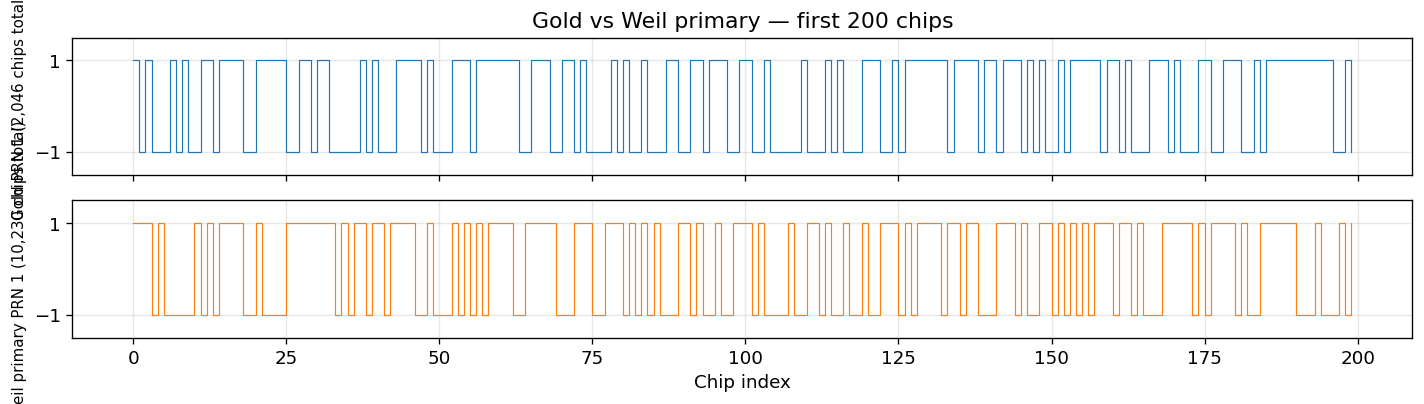

In [7]:
# Compare Gold and Weil code lengths visually
fig, axes = plt.subplots(2, 1, figsize=(12, 3.5), sharex=True)

# Show 200 chips of each
n_show = 200
for ax, code, label, color in [
    (axes[0], gold_1, f"Gold PRN 1 ({GOLD_CHIP_LENGTH:,} chips total)", "C0"),
    (axes[1], weil_1, f"Weil primary PRN 1 ({WEIL_10230_CHIP_LENGTH:,} chips total)", "C1"),
]:
    bipolar = np.where(code[:n_show] == 0, 1.0, -1.0)
    ax.step(range(n_show), bipolar, where="post", linewidth=0.7, color=color)
    ax.set_ylabel(label, fontsize=9)
    ax.set_ylim(-1.5, 1.5)
    ax.set_yticks([-1, 1])

axes[1].set_xlabel("Chip index")
axes[0].set_title("Gold vs Weil primary — first 200 chips")
fig.tight_layout()
plt.show()

---

## 4. Tertiary codes (short Weil)

> **Spec:** §2.3.5.3.2 (LSIS-224), Appendix E — *Weil Tertiary Code Generation*

The tertiary code is another Weil-family sequence, but shorter: **1,500 chips**
constructed from a Legendre sequence of prime length $p = 1499$ with one zero
appended.

$$W_t[n] = L_{1499}[n] \oplus L_{1499}[(n + k_t) \bmod 1499] \quad \text{for } n = 0 \ldots 1498$$
$$W_t[1499] = 0 \quad \text{(appended)}$$

Each PRN gets a unique shift $k_t$ from Appendix E. The tertiary code's purpose
becomes clear in Section 6 (tiered assembly): it modulates the primary code
across epochs, extending the effective code length for long-integration
acquisition.

Weil tertiary PRN 1: length = 1,500, ones = 750
Weil tertiary PRN 2: length = 1,500, ones = 750

Last 5 chips of PRN 1: [0, 1, 1, 0, 0]
  (last chip is always 0 — the appended zero)


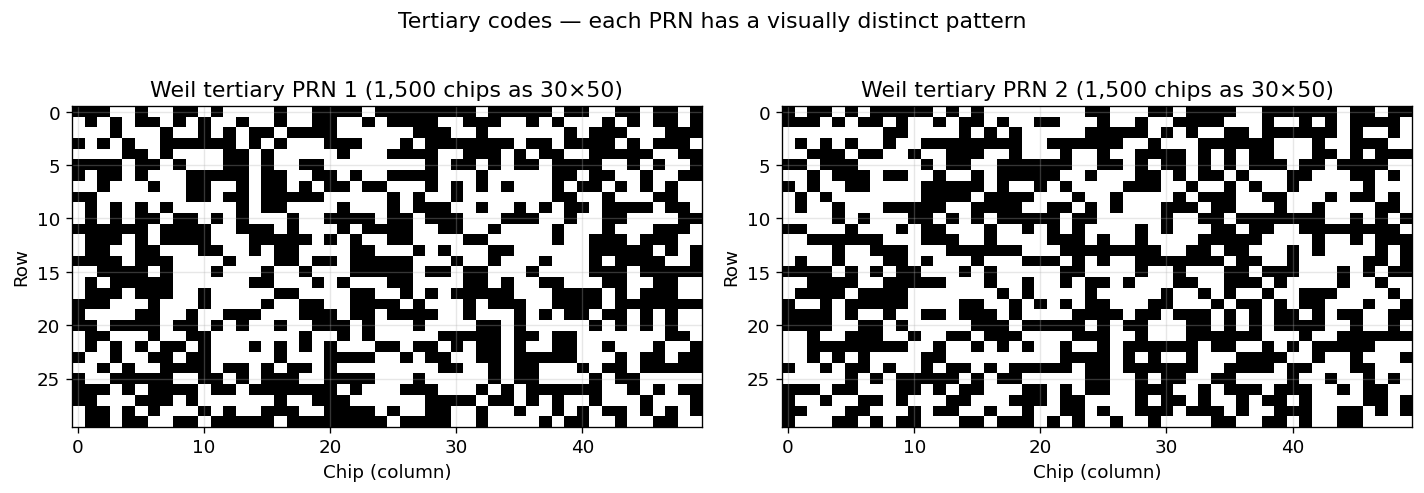


One tertiary chip is applied per epoch (2 ms).
Full tertiary code spans 1500 × 2 ms = 3 s
  → exactly 1/4 of a 12 s frame. The code repeats 4× per frame.


In [8]:
# Generate tertiary codes and visualise
tert_1 = weil1500_code(1)
tert_2 = weil1500_code(2)

print(f"Weil tertiary PRN 1: length = {len(tert_1):,}, ones = {tert_1.sum()}")
print(f"Weil tertiary PRN 2: length = {len(tert_2):,}, ones = {tert_2.sum()}")
print(f"\nLast 5 chips of PRN 1: {tert_1[-5:].tolist()}")
print(f"  (last chip is always 0 — the appended zero)")

# Visualise the tertiary code as a 2D image (30 rows × 50 cols = 1500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, code, prn in [(axes[0], tert_1, 1), (axes[1], tert_2, 2)]:
    ax.imshow(code.reshape(30, 50), cmap="binary", aspect="auto", interpolation="nearest")
    ax.set_title(f"Weil tertiary PRN {prn} (1,500 chips as 30×50)")
    ax.set_xlabel("Chip (column)")
    ax.set_ylabel("Row")

fig.suptitle("Tertiary codes — each PRN has a visually distinct pattern", y=1.02)
fig.tight_layout()
plt.show()

print(f"\nOne tertiary chip is applied per epoch (2 ms).")
print(f"Full tertiary code spans {TERTIARY_CODE_LENGTH} × 2 ms = {TERTIARY_CODE_LENGTH * 2 / 1000:.0f} s")
print(f"  → exactly 1/4 of a 12 s frame. The code repeats 4× per frame.")

---

## 5. Secondary codes (epoch markers)

> **Spec:** §2.3.5.3.2 (LSIS-223), Table 10 — *Secondary Code Sequences*

The secondary codes are the simplest: just **4 chips** each, assigned from a
fixed set of four sequences.

| Code | Binary | Hex | Decimal |
|------|--------|-----|---------|
| S0 | 1110 | E | 14 |
| S1 | 0111 | 7 | 7 |
| S2 | 1011 | B | 11 |
| S3 | 1101 | D | 13 |

Each node is assigned one secondary code (Table 11: node $N$ gets $S_{(N-1) \bmod 4}$).
During transmission, the secondary code repeats across 4-epoch groups: one chip of
the secondary code is applied per primary code epoch (2 ms), so the full secondary
code spans $4 \times 2 = 8$ ms.

The secondary code serves as a **short-term phase marker** — it helps the receiver
quickly resolve the epoch alignment within a group of 4 primary epochs.

In [9]:
# Secondary codes are hardcoded in the spec (Table 10)
secondary_codes = {
    "S0": [1, 1, 1, 0],
    "S1": [0, 1, 1, 1],
    "S2": [1, 0, 1, 1],
    "S3": [1, 1, 0, 1],
}

print("Secondary codes (Table 10):")
for name, code in secondary_codes.items():
    hex_val = sum(b << (3 - i) for i, b in enumerate(code))
    print(f"  {name}: {''.join(str(b) for b in code)}  (hex {hex_val:X})")

# Show which secondary code each interim node gets
print("\nInterim assignments (Table 11):")
for node in range(1, 13):
    p_prn, s_idx, t_prn, t_phase = default_matched_assignment(node)
    print(f"  Node {node:2d} → PRN_I={p_prn:3d}, S{s_idx}, "
          f"PRN_Q_tert={t_prn:3d}, phase={t_phase}")

Secondary codes (Table 10):
  S0: 1110  (hex E)
  S1: 0111  (hex 7)
  S2: 1011  (hex B)
  S3: 1101  (hex D)

Interim assignments (Table 11):
  Node  1 → PRN_I=  1, S0, PRN_Q_tert=  1, phase=0
  Node  2 → PRN_I=  2, S1, PRN_Q_tert=  2, phase=0
  Node  3 → PRN_I=  3, S2, PRN_Q_tert=  3, phase=0
  Node  4 → PRN_I=  4, S3, PRN_Q_tert=  4, phase=0
  Node  5 → PRN_I=  5, S0, PRN_Q_tert=  5, phase=0
  Node  6 → PRN_I=  6, S1, PRN_Q_tert=  6, phase=0
  Node  7 → PRN_I=  7, S2, PRN_Q_tert=  7, phase=0
  Node  8 → PRN_I=  8, S3, PRN_Q_tert=  8, phase=0
  Node  9 → PRN_I=  9, S0, PRN_Q_tert=  9, phase=0
  Node 10 → PRN_I= 10, S1, PRN_Q_tert= 10, phase=0
  Node 11 → PRN_I= 11, S2, PRN_Q_tert= 11, phase=0
  Node 12 → PRN_I= 12, S3, PRN_Q_tert= 12, phase=0


---

## 6. Tiered code assembly — the matched code

> **Spec:** §2.3.5.2 — *Tiered Code Generation*,
> LSIS-160, LSIS-170, LSIS-171, LSIS-220

On the Q-channel, the three code layers combine into a single **matched code**
that the receiver correlates against. The figure below shows how the Data (I)
and Pilot (Q) channels are synchronised — the I-channel Gold code aligns with
data symbols, while the Q-channel assembles primary, secondary, and tertiary
codes into the tiered ranging code:

![Figure 3: Data and Pilot Channel Code and Data Synchronization.
*(Source: LSIS V1.0, §2.3.4, Figure 3)*](figures/fig3_iq_sync.png)

The assembly happens epoch-by-epoch
(one epoch = one primary code period = 2 ms = 10,230 chips at 5.115 Mchip/s):

$$\text{matched}[n, e] = \text{primary}[n] \oplus \text{secondary}[e \bmod 4] \oplus \text{tertiary}[(e \bmod 1500)]$$

where:
- $n$ is the chip index within the epoch (0 to 10,229)
- $e$ is the epoch index within the 12-second frame (0 to 5,999)
- secondary chip is constant across all 10,230 chips within one epoch (it flips the *entire* epoch)
- tertiary chip is also constant per epoch (one chip of the 1,500-chip tertiary code per epoch)

The block diagram below shows how a single clock is divided down to drive
primary, secondary, and tertiary code generators, whose outputs are XOR-ed
to produce $C_{AFS-Q}$:

![Figure 4: Tiered Codes Generation with Secondary and Tertiary Codes.
*(Source: LSIS V1.0, §2.3.5.2, Figure 4)*](figures/fig4_tiered_generation.png)

**Synchronisation rules** (critical for interoperability):
- **LSIS-160**: Data symbols align with primary code boundaries
- **LSIS-170**: Secondary code aligns with primary code boundaries
- **LSIS-171**: Tertiary code aligns with secondary code boundaries
- **LSIS-220**: Tertiary code resets at the start of each frame

The total effective code length is $10{,}230 \times 1{,}500 \times 4 = 61{,}380{,}000$ chips
(~12 seconds), giving the receiver enormous processing gain for weak-signal
acquisition in cislunar space.

In [10]:
# Generate matched code epochs and show how secondary/tertiary modulate the primary
prn = 1
n_epochs = 8  # Show 8 epochs (16 ms)

# Get the assignment for this PRN
p_prn, s_idx, t_prn, t_phase = default_matched_assignment(prn)
sec = secondary_codes[f"S{s_idx}"]
tert = weil1500_code(t_prn)

print(f"PRN {prn} matched code assembly:")
print(f"  Primary:   Weil-10230 PRN {p_prn}")
print(f"  Secondary: S{s_idx} = {sec}")
print(f"  Tertiary:  Weil-1500 PRN {t_prn}, phase offset = {t_phase}")
print()

# Show the XOR logic for the first 8 epochs
print(f"{'Epoch':>5}  {'Sec chip':>8}  {'Tert chip':>9}  {'XOR mod':>7}  {'Effect on primary':>20}")
print("-" * 60)
for e in range(n_epochs):
    s_chip = sec[e % SECONDARY_CODE_LENGTH]
    t_chip = tert[(e + t_phase) % TERTIARY_CODE_LENGTH]
    xor_mod = s_chip ^ t_chip
    effect = "inverted" if xor_mod else "unchanged"
    print(f"{e:5d}  {s_chip:>8d}  {t_chip:>9d}  {xor_mod:>7d}  {effect:>20}")

PRN 1 matched code assembly:
  Primary:   Weil-10230 PRN 1
  Secondary: S0 = [1, 1, 1, 0]
  Tertiary:  Weil-1500 PRN 1, phase offset = 0

Epoch  Sec chip  Tert chip  XOR mod     Effect on primary
------------------------------------------------------------
    0         1          1        0             unchanged
    1         1          1        0             unchanged
    2         1          1        0             unchanged
    3         0          0        0             unchanged
    4         1          0        1              inverted
    5         1          1        0             unchanged
    6         1          0        1              inverted
    7         0          0        0             unchanged


Manual XOR matches LunaLink matched_code_epoch() for epoch 0


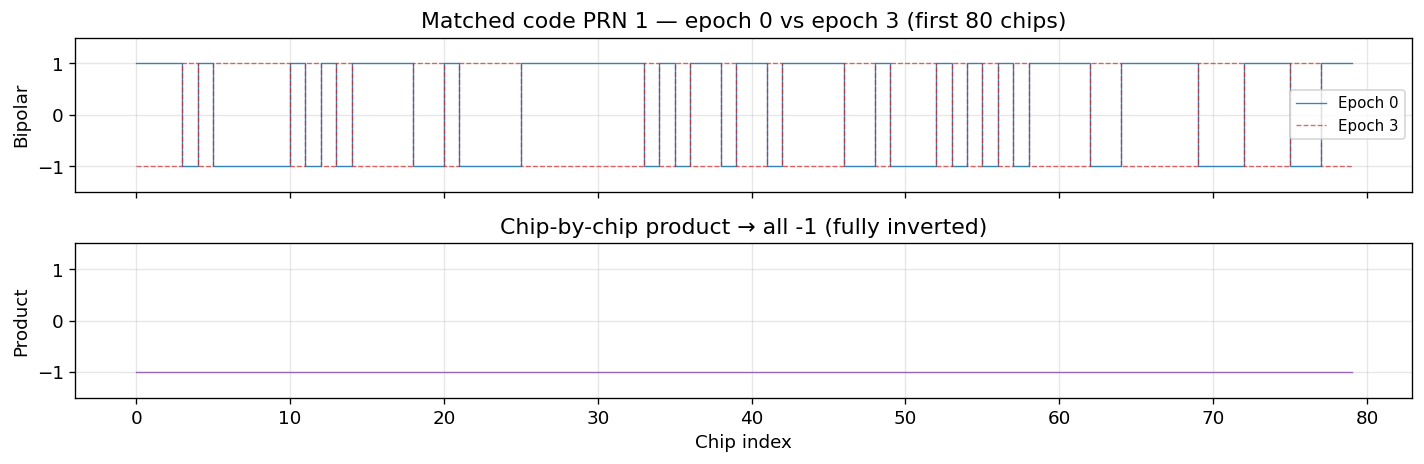

Epoch 0: secondary=1, tertiary=1, XOR modifier=0
Epoch 3: secondary=0, tertiary=0, XOR modifier=0
→ The secondary/tertiary XOR either leaves the primary unchanged or inverts it entirely.


In [11]:
# Use LunaLink's matched_code_epoch to get the assembled code
# and verify it matches our manual XOR computation

primary = weil10230_code(p_prn)

# Manual computation for epoch 0
s_chip_0 = sec[0 % SECONDARY_CODE_LENGTH]
t_chip_0 = tert[(0 + t_phase) % TERTIARY_CODE_LENGTH]
manual_epoch_0 = (primary ^ s_chip_0 ^ t_chip_0).astype(np.uint8)

# LunaLink computation (positional args: prn_id, epoch_index)
lunalink_epoch_0 = matched_code_epoch(prn, 0)

assert np.array_equal(manual_epoch_0, lunalink_epoch_0), "Mismatch!"
print("Manual XOR matches LunaLink matched_code_epoch() for epoch 0")

# --- Better visualisation: overlay flipped vs non-flipped epochs ---
chips_show = 80
mc_0 = matched_code_epoch(prn, 0)  # epoch 0: S=1, T=1 → XOR=0 → unchanged
mc_3 = matched_code_epoch(prn, 3)  # epoch 3: S=0, T=? → may be flipped

bp_0 = np.where(mc_0[:chips_show] == 0, 1.0, -1.0)
bp_3 = np.where(mc_3[:chips_show] == 0, 1.0, -1.0)

fig, axes = plt.subplots(2, 1, figsize=(12, 4), sharex=True)

# Top: epoch 0 and epoch 3 side by side
axes[0].step(range(chips_show), bp_0, where="post", linewidth=0.8,
             color="C0", label="Epoch 0", alpha=0.9)
axes[0].step(range(chips_show), bp_3, where="post", linewidth=0.8,
             color="C3", label="Epoch 3", alpha=0.7, linestyle="--")
axes[0].set_ylabel("Bipolar")
axes[0].set_ylim(-1.5, 1.5)
axes[0].set_title(f"Matched code PRN {prn} — epoch 0 vs epoch 3 (first {chips_show} chips)")
axes[0].legend(fontsize=9)

# Bottom: product (shows +1 where same, -1 where flipped)
product = bp_0 * bp_3
axes[1].step(range(chips_show), product, where="post", linewidth=0.8, color="C4")
axes[1].set_ylabel("Product")
axes[1].set_ylim(-1.5, 1.5)
flipped = np.sum(product < 0) / chips_show * 100
axes[1].set_title(f"Chip-by-chip product → {'all +1 (identical epochs)' if flipped == 0 else f'all -1 (fully inverted)' if flipped == 100 else f'{flipped:.0f}% inverted'}")
axes[1].set_xlabel("Chip index")

fig.tight_layout()
plt.show()

s0 = sec[0 % SECONDARY_CODE_LENGTH]
t0 = tert[(0 + t_phase) % TERTIARY_CODE_LENGTH]
s3 = sec[3 % SECONDARY_CODE_LENGTH]
t3 = tert[(3 + t_phase) % TERTIARY_CODE_LENGTH]
print(f"Epoch 0: secondary={s0}, tertiary={t0}, XOR modifier={s0^t0}")
print(f"Epoch 3: secondary={s3}, tertiary={t3}, XOR modifier={s3^t3}")
print(f"→ The secondary/tertiary XOR either leaves the primary unchanged or inverts it entirely.")

---

## 7. Correlation properties — why these codes work

The whole point of spreading codes is their
[correlation](https://en.wikipedia.org/wiki/Correlation) behaviour. Let's compute
and visualise the two key metrics:

1. **[Autocorrelation](https://en.wikipedia.org/wiki/Autocorrelation)** — correlate
   a code with a time-shifted copy of itself. A sharp peak at zero lag means the
   receiver can precisely measure time of arrival.
2. **[Cross-correlation](https://en.wikipedia.org/wiki/Cross-correlation)** —
   correlate codes from different PRNs. Low cross-correlation means multiple
   satellites don't interfere.

For a binary code $c[n] \in \{0, 1\}$ of length $N$, we compute
[circular correlation](https://en.wikipedia.org/wiki/Circular_convolution)
in bipolar representation ($b[n] = 1 - 2c[n] \in \{-1, +1\}$):

$$R(\tau) = \frac{1}{N} \sum_{n=0}^{N-1} b[n] \cdot b[(n + \tau) \bmod N]$$

At $\tau = 0$, $R(0) = 1$ (perfect self-alignment). For a good code, $|R(\tau)| \ll 1$
for all $\tau \neq 0$.

We use circular (not linear) correlation because the codes repeat periodically in
the transmitted signal — the receiver sees an endless stream of code periods, so
the correlation is inherently cyclic. The computation is efficient via the
[FFT](https://en.wikipedia.org/wiki/Fast_Fourier_transform) using the
[correlation theorem](https://en.wikipedia.org/wiki/Cross-correlation#Properties):
$R = \mathcal{F}^{-1}\{F \cdot F^*\}$.

In [12]:
def circular_correlation(code: np.ndarray) -> np.ndarray:
    """Compute normalised circular autocorrelation via FFT (fast)."""
    bipolar = 1.0 - 2.0 * code.astype(np.float64)
    N = len(bipolar)
    F = np.fft.fft(bipolar)
    R = np.fft.ifft(F * np.conj(F)).real / N
    return R


def cross_correlation(code_a: np.ndarray, code_b: np.ndarray) -> np.ndarray:
    """Compute normalised circular cross-correlation via FFT."""
    ba = 1.0 - 2.0 * code_a.astype(np.float64)
    bb = 1.0 - 2.0 * code_b.astype(np.float64)
    N = len(ba)
    R = np.fft.ifft(np.fft.fft(ba) * np.conj(np.fft.fft(bb))).real / N
    return R

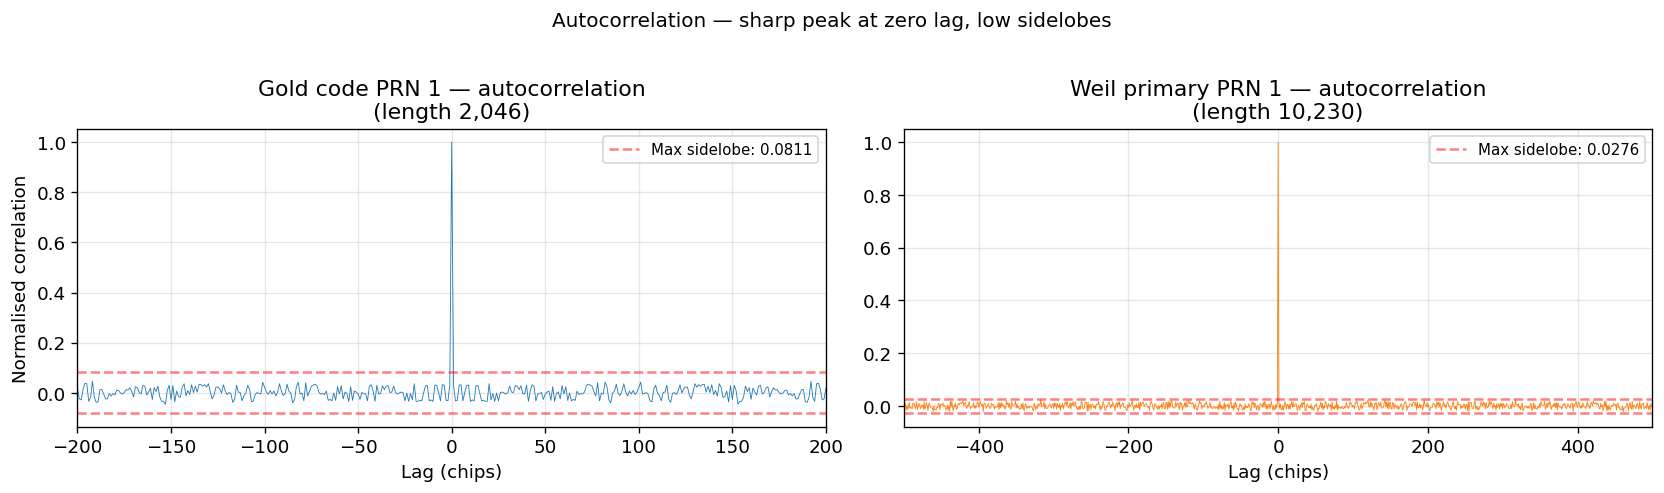

Gold max sidelobe:       0.0811  (1/12 of peak)
Weil primary max sidelobe: 0.0276  (1/36 of peak)

Weil primary sidelobes are ~2.9× lower than Gold — better ranging precision.


In [13]:
# --- Autocorrelation: Gold vs Weil primary ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gold code autocorrelation
R_gold = circular_correlation(gold_1)
lags_gold = np.arange(len(R_gold)) - len(R_gold) // 2
R_gold_shifted = np.fft.fftshift(R_gold)
axes[0].plot(lags_gold, R_gold_shifted, linewidth=0.5)
axes[0].set_title(f"Gold code PRN 1 — autocorrelation\n"
                   f"(length {GOLD_CHIP_LENGTH:,})")
axes[0].set_xlabel("Lag (chips)")
axes[0].set_ylabel("Normalised correlation")
axes[0].set_xlim(-200, 200)
peak_gold = np.max(np.abs(R_gold[1:]))  # Exclude zero-lag
axes[0].axhline(y=peak_gold, color="r", linestyle="--", alpha=0.5,
                label=f"Max sidelobe: {peak_gold:.4f}")
axes[0].axhline(y=-peak_gold, color="r", linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9)

# Weil primary autocorrelation
R_weil = circular_correlation(weil_1)
lags_weil = np.arange(len(R_weil)) - len(R_weil) // 2
R_weil_shifted = np.fft.fftshift(R_weil)
axes[1].plot(lags_weil, R_weil_shifted, linewidth=0.5, color="C1")
axes[1].set_title(f"Weil primary PRN 1 — autocorrelation\n"
                   f"(length {WEIL_10230_CHIP_LENGTH:,})")
axes[1].set_xlabel("Lag (chips)")
axes[1].set_xlim(-500, 500)
peak_weil = np.max(np.abs(R_weil[1:]))
axes[1].axhline(y=peak_weil, color="r", linestyle="--", alpha=0.5,
                label=f"Max sidelobe: {peak_weil:.4f}")
axes[1].axhline(y=-peak_weil, color="r", linestyle="--", alpha=0.5)
axes[1].legend(fontsize=9)

fig.suptitle("Autocorrelation — sharp peak at zero lag, low sidelobes",
             fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

print(f"Gold max sidelobe:       {peak_gold:.4f}  (1/{1/peak_gold:.0f} of peak)")
print(f"Weil primary max sidelobe: {peak_weil:.4f}  (1/{1/peak_weil:.0f} of peak)")
print(f"\nWeil primary sidelobes are ~{peak_gold/peak_weil:.1f}× lower than Gold"
      f" — better ranging precision.")

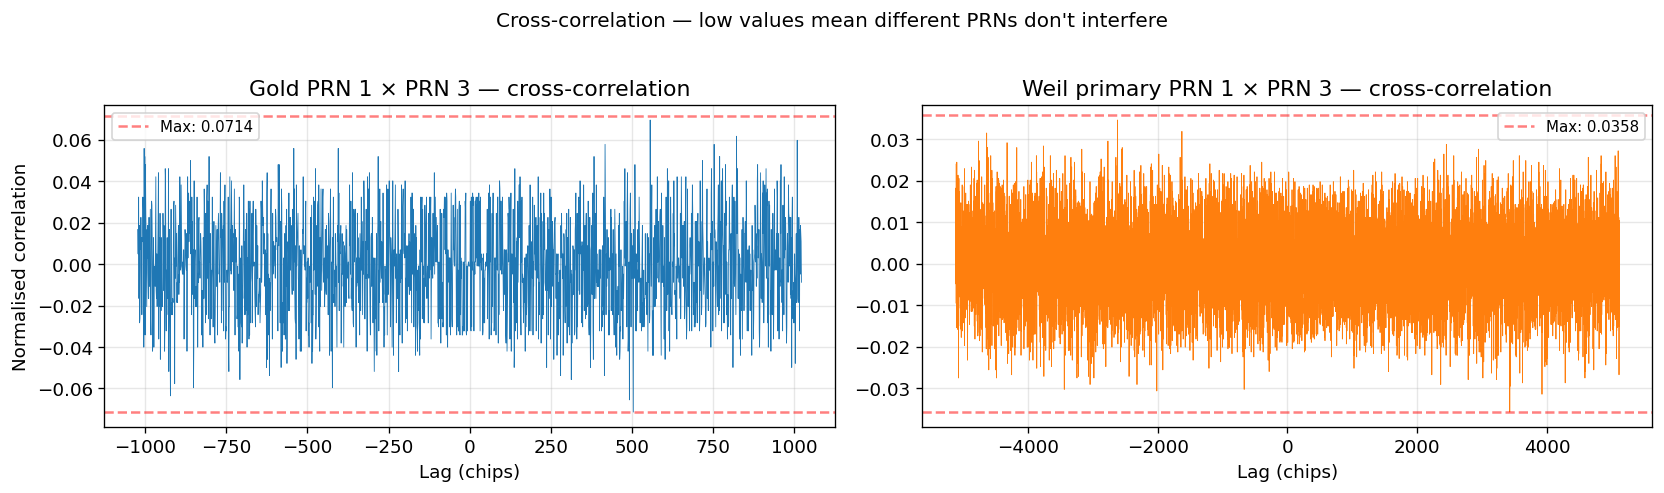

Gold max cross-correlation:  0.0714
Weil max cross-correlation:  0.0358

Both are well below 0.05 — excellent separation between PRNs.


In [14]:
# --- Cross-correlation: how well do different PRNs separate? ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gold cross-correlation: PRN 1 vs PRN 3
Rx_gold = cross_correlation(gold_1, gold_3)
lags_gold = np.arange(len(Rx_gold)) - len(Rx_gold) // 2
Rx_gold_shifted = np.fft.fftshift(Rx_gold)
axes[0].plot(lags_gold, Rx_gold_shifted, linewidth=0.5)
axes[0].set_title("Gold PRN 1 × PRN 3 — cross-correlation")
axes[0].set_xlabel("Lag (chips)")
axes[0].set_ylabel("Normalised correlation")
peak_xc_gold = np.max(np.abs(Rx_gold))
axes[0].axhline(y=peak_xc_gold, color="r", linestyle="--", alpha=0.5,
                label=f"Max: {peak_xc_gold:.4f}")
axes[0].axhline(y=-peak_xc_gold, color="r", linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9)

# Weil primary cross-correlation: PRN 1 vs PRN 3
Rx_weil = cross_correlation(weil_1, weil_3)
lags_weil = np.arange(len(Rx_weil)) - len(Rx_weil) // 2
Rx_weil_shifted = np.fft.fftshift(Rx_weil)
axes[1].plot(lags_weil, Rx_weil_shifted, linewidth=0.5, color="C1")
axes[1].set_title("Weil primary PRN 1 × PRN 3 — cross-correlation")
axes[1].set_xlabel("Lag (chips)")
peak_xc_weil = np.max(np.abs(Rx_weil))
axes[1].axhline(y=peak_xc_weil, color="r", linestyle="--", alpha=0.5,
                label=f"Max: {peak_xc_weil:.4f}")
axes[1].axhline(y=-peak_xc_weil, color="r", linestyle="--", alpha=0.5)
axes[1].legend(fontsize=9)

fig.suptitle("Cross-correlation — low values mean different PRNs don't interfere",
             fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

print(f"Gold max cross-correlation:  {peak_xc_gold:.4f}")
print(f"Weil max cross-correlation:  {peak_xc_weil:.4f}")
print(f"\nBoth are well below 0.05 — excellent separation between PRNs.")

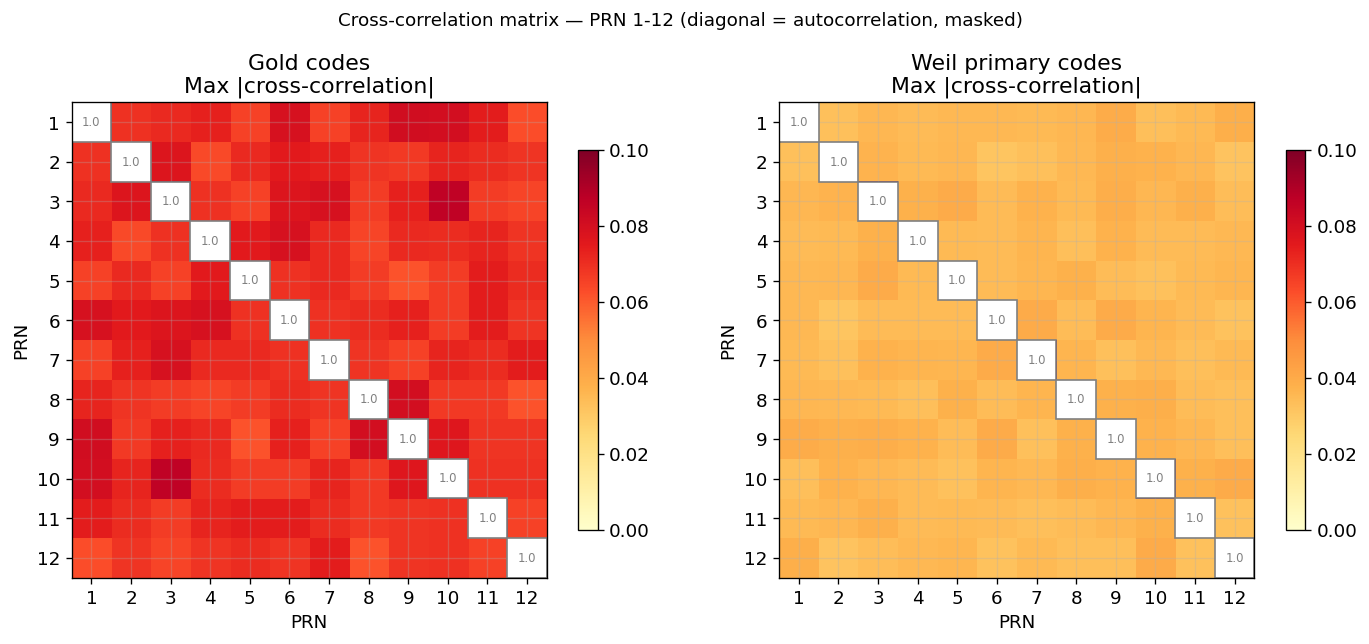

Gold  — max cross-corr: 0.0860, mean: 0.0708
Weil  — max cross-corr: 0.0397, mean: 0.0356


In [15]:
# --- Cross-correlation heatmap across multiple PRNs ---
# Compute max absolute cross-correlation for PRN pairs 1-12 (interim nodes)
n_prns = 12
xc_matrix_gold = np.zeros((n_prns, n_prns))
xc_matrix_weil = np.zeros((n_prns, n_prns))

gold_codes = [prn_code(p) for p in range(1, n_prns + 1)]
weil_codes = [weil10230_code(p) for p in range(1, n_prns + 1)]

for i in range(n_prns):
    for j in range(n_prns):
        if i == j:
            xc_matrix_gold[i, j] = 1.0
            xc_matrix_weil[i, j] = 1.0
        else:
            Rx = cross_correlation(gold_codes[i], gold_codes[j])
            xc_matrix_gold[i, j] = np.max(np.abs(Rx))
            Rx = cross_correlation(weil_codes[i], weil_codes[j])
            xc_matrix_weil[i, j] = np.max(np.abs(Rx))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, mat, title in [
    (axes[0], xc_matrix_gold, "Gold codes"),
    (axes[1], xc_matrix_weil, "Weil primary codes"),
]:
    im = ax.imshow(mat, vmin=0, vmax=0.1, cmap="YlOrRd", aspect="equal")
    ax.set_title(f"{title}\nMax |cross-correlation|")
    ax.set_xlabel("PRN")
    ax.set_ylabel("PRN")
    ax.set_xticks(range(n_prns))
    ax.set_yticks(range(n_prns))
    ax.set_xticklabels(range(1, n_prns + 1))
    ax.set_yticklabels(range(1, n_prns + 1))
    plt.colorbar(im, ax=ax, shrink=0.8)

    # Mask diagonal
    for k in range(n_prns):
        ax.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1,
                                    fill=True, color="white", ec="gray"))
        ax.text(k, k, "1.0", ha="center", va="center", fontsize=7, color="gray")

fig.suptitle("Cross-correlation matrix — PRN 1-12 (diagonal = autocorrelation, masked)",
             fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

# Summary statistics
off_diag_gold = xc_matrix_gold[~np.eye(n_prns, dtype=bool)]
off_diag_weil = xc_matrix_weil[~np.eye(n_prns, dtype=bool)]
print(f"Gold  — max cross-corr: {off_diag_gold.max():.4f}, "
      f"mean: {off_diag_gold.mean():.4f}")
print(f"Weil  — max cross-corr: {off_diag_weil.max():.4f}, "
      f"mean: {off_diag_weil.mean():.4f}")

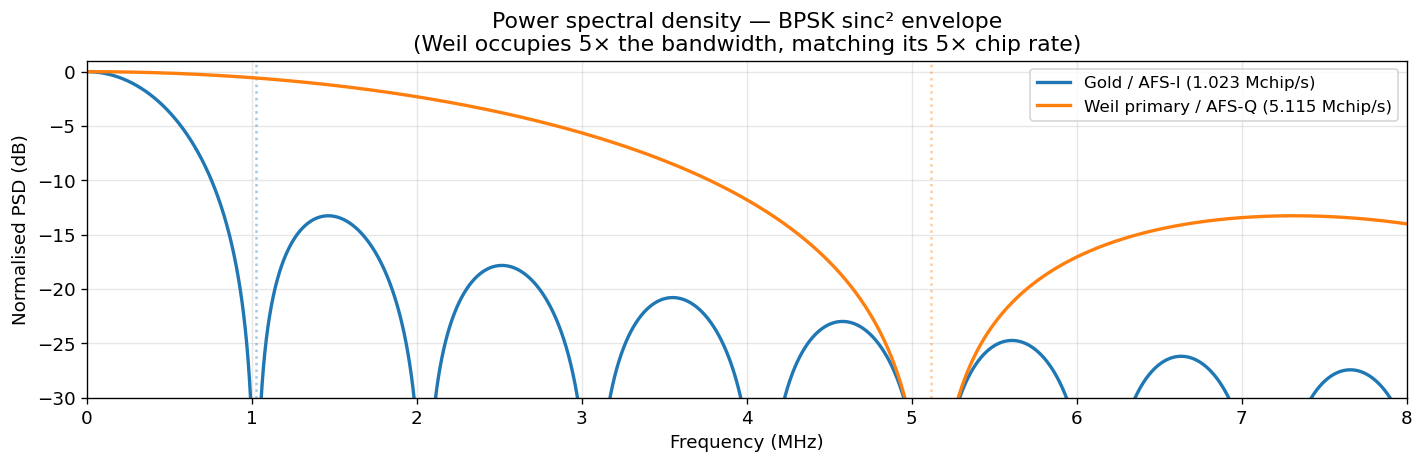

The Gold code's main lobe (first null) is at 1.023 MHz.
The Weil code's main lobe (first null) is at 5.115 MHz.
This 5× wider bandwidth gives the Q-channel finer time resolution — 
each chip is 5× shorter, so ranging precision improves by a factor of 5.


In [16]:
# --- Power Spectral Density: Gold vs Weil primary ---
# A BPSK-spread PRN code has a sinc² PSD envelope with main lobe width = 2×chip_rate.

fig, ax = plt.subplots(figsize=(12, 4))

freqs = np.linspace(0.001, 8, 5000)  # MHz

for chip_rate_mhz, label, color in [
    (1.023, "Gold / AFS-I (1.023 Mchip/s)", "C0"),
    (5.115, "Weil primary / AFS-Q (5.115 Mchip/s)", "C1"),
]:
    # Theoretical PSD: sinc²(f / chip_rate) — normalised
    Tc = 1.0 / chip_rate_mhz  # chip period in µs
    psd = (Tc * np.sinc(freqs * Tc)) ** 2
    psd_db = 10 * np.log10(psd / psd.max())
    ax.plot(freqs, psd_db, linewidth=2, color=color, label=label)
    ax.axvline(chip_rate_mhz, color=color, linestyle=":", alpha=0.4)

ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Normalised PSD (dB)")
ax.set_title("Power spectral density — BPSK sinc² envelope\n"
             "(Weil occupies 5× the bandwidth, matching its 5× chip rate)")
ax.set_xlim(0, 8)
ax.set_ylim(-30, 1)
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()

print(f"The Gold code's main lobe (first null) is at {1.023:.3f} MHz.")
print(f"The Weil code's main lobe (first null) is at {5.115:.3f} MHz.")
print(f"This 5× wider bandwidth gives the Q-channel finer time resolution — ")
print(f"each chip is 5× shorter, so ranging precision improves by a factor of 5.")

---

## 8. Validation against Annex 3

> **Spec:** Annex 3 — *PRN Spreading Codes* (electronic reference data)

The LSIS specification includes reference hexadecimal codes for all 210 PRNs in
Annex 3. Any conformant implementation must produce **bit-exact** matches.

Let's load the official hex files and compare them chip-by-chip against LunaLink's
output. This is the ultimate interoperability test — if two implementations agree
on the hex codes, they will produce identical signals.

In [17]:
# --- Bit-exact validation against Annex 3 reference hex codes ---
import re, time, pathlib

REFS = pathlib.Path("../docs/references")

def load_annex3_hex(filepath: pathlib.Path) -> list[str]:
    """Extract hex codes from an Annex 3 file.

    Handles two formats:
    - Quoted: "ABCDEF..." (Gold codes, Weil tertiary)
    - Raw lines: ABCDEF... one per line (Weil primary)
    """
    text = filepath.read_text()
    # Try quoted format first
    quoted = re.findall(r'"([0-9A-Fa-f]+)"', text)
    if quoted:
        return quoted
    # Fall back to raw long hex lines (≥100 hex chars)
    return re.findall(r'([0-9A-Fa-f]{100,})', text)

def hex_to_bits(hexstr: str, code_length: int) -> np.ndarray:
    """Convert hex string to binary array, stripping padding MSBs per Annex 3 convention."""
    total_bits = len(hexstr) * 4
    bits = bin(int(hexstr, 16))[2:].zfill(total_bits)
    # Remove leading padding bits (total_bits - code_length)
    pad = total_bits - code_length
    return np.array([int(b) for b in bits[pad:]], dtype=np.uint8)

# Load all three Annex 3 files
gold_hex = load_annex3_hex(REFS / "006_GoldCode2046hex210prns.txt")
weil_p_hex = load_annex3_hex(REFS / "007_l1cp_hex210prns.txt")
weil_t_hex = load_annex3_hex(REFS / "008_Weil1500hex210prns.txt")

print(f"Loaded Annex 3 reference codes:")
print(f"  Gold codes:    {len(gold_hex)} PRNs")
print(f"  Weil primary:  {len(weil_p_hex)} PRNs")
print(f"  Weil tertiary: {len(weil_t_hex)} PRNs")

# Validate ALL 210 PRNs against LunaLink
start = time.perf_counter()
gold_match = weil_p_match = weil_t_match = 0

for prn_idx in range(PRN_COUNT):
    prn_id = prn_idx + 1

    # Gold
    ref = hex_to_bits(gold_hex[prn_idx], GOLD_CHIP_LENGTH)
    gen = prn_code(prn_id)
    if np.array_equal(ref, gen):
        gold_match += 1

    # Weil primary
    ref = hex_to_bits(weil_p_hex[prn_idx], WEIL_10230_CHIP_LENGTH)
    gen = weil10230_code(prn_id)
    if np.array_equal(ref, gen):
        weil_p_match += 1

    # Weil tertiary
    ref = hex_to_bits(weil_t_hex[prn_idx], WEIL_1500_CHIP_LENGTH)
    gen = weil1500_code(prn_id)
    if np.array_equal(ref, gen):
        weil_t_match += 1

elapsed = time.perf_counter() - start

print(f"\n{'Code family':<25s} {'Match':>5s} / {'Total':>5s}  {'Result':<6s}")
print("-" * 50)
for name, match, total in [
    ("Gold (2,046 chips)", gold_match, PRN_COUNT),
    ("Weil primary (10,230)", weil_p_match, PRN_COUNT),
    ("Weil tertiary (1,500)", weil_t_match, PRN_COUNT),
]:
    status = "PASS" if match == total else "FAIL"
    print(f"{name:<25s} {match:>5d} / {total:>5d}  {status:<6s}")

total_checks = PRN_COUNT * 3
total_pass = gold_match + weil_p_match + weil_t_match
print(f"\n{total_pass:,} / {total_checks:,} bit-exact matches in {elapsed:.2f}s — "
      f"{'ALL PASS' if total_pass == total_checks else 'FAILURES DETECTED'}")

# Spot-check: show the hex for PRN 1 Gold code (first and last 24 chips)
g1 = prn_code(1)
first_hex = hex(int("".join(str(b) for b in g1[:24]), 2))[2:].upper()
last_hex = hex(int("".join(str(b) for b in g1[-24:]), 2))[2:].upper()
print(f"\nSpot check — PRN 1 Gold code:")
print(f"  First 24 chips (hex): {first_hex}")
print(f"  Last 24 chips (hex):  {last_hex}")
print(f"  Annex 3 Table C-1:    first={gold_hex[0][:6].upper()}, last={gold_hex[0][-6:].upper()}")

Loaded Annex 3 reference codes:
  Gold codes:    210 PRNs
  Weil primary:  210 PRNs
  Weil tertiary: 210 PRNs

Code family               Match / Total  Result
--------------------------------------------------
Gold (2,046 chips)          210 /   210  PASS  
Weil primary (10,230)       210 /   210  PASS  
Weil tertiary (1,500)       210 /   210  PASS  

630 / 630 bit-exact matches in 0.18s — ALL PASS

Spot check — PRN 1 Gold code:
  First 24 chips (hex): 5D6430
  Last 24 chips (hex):  CF00CE
  Annex 3 Table C-1:    first=17590C, last=CF00CE


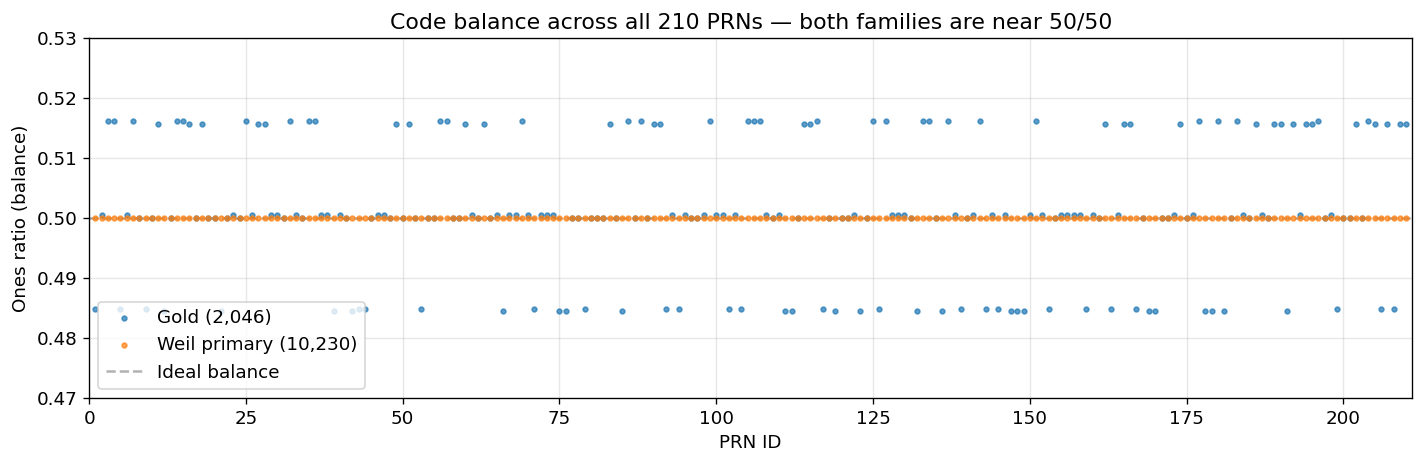

Gold balance:  min=0.4844, max=0.5161, mean=0.5012
Weil balance:  min=0.5000, max=0.5000, mean=0.5000


In [18]:
# Visualise balance (ones ratio) across all 210 PRNs
gold_balance = np.array([prn_code(p).sum() / GOLD_CHIP_LENGTH
                         for p in range(1, PRN_COUNT + 1)])
weil_balance = np.array([weil10230_code(p).sum() / WEIL_10230_CHIP_LENGTH
                         for p in range(1, PRN_COUNT + 1)])

fig, ax = plt.subplots(figsize=(12, 4))
prns = np.arange(1, PRN_COUNT + 1)
ax.scatter(prns, gold_balance, s=8, alpha=0.7, label="Gold (2,046)", zorder=3)
ax.scatter(prns, weil_balance, s=8, alpha=0.7, label="Weil primary (10,230)", zorder=3)
ax.axhline(y=0.5, color="k", linestyle="--", alpha=0.3, label="Ideal balance")
ax.set_xlabel("PRN ID")
ax.set_ylabel("Ones ratio (balance)")
ax.set_title("Code balance across all 210 PRNs — both families are near 50/50")
ax.set_xlim(0, 211)
ax.set_ylim(0.47, 0.53)
ax.legend()
fig.tight_layout()
plt.show()

print(f"Gold balance:  min={gold_balance.min():.4f}, "
      f"max={gold_balance.max():.4f}, mean={gold_balance.mean():.4f}")
print(f"Weil balance:  min={weil_balance.min():.4f}, "
      f"max={weil_balance.max():.4f}, mean={weil_balance.mean():.4f}")

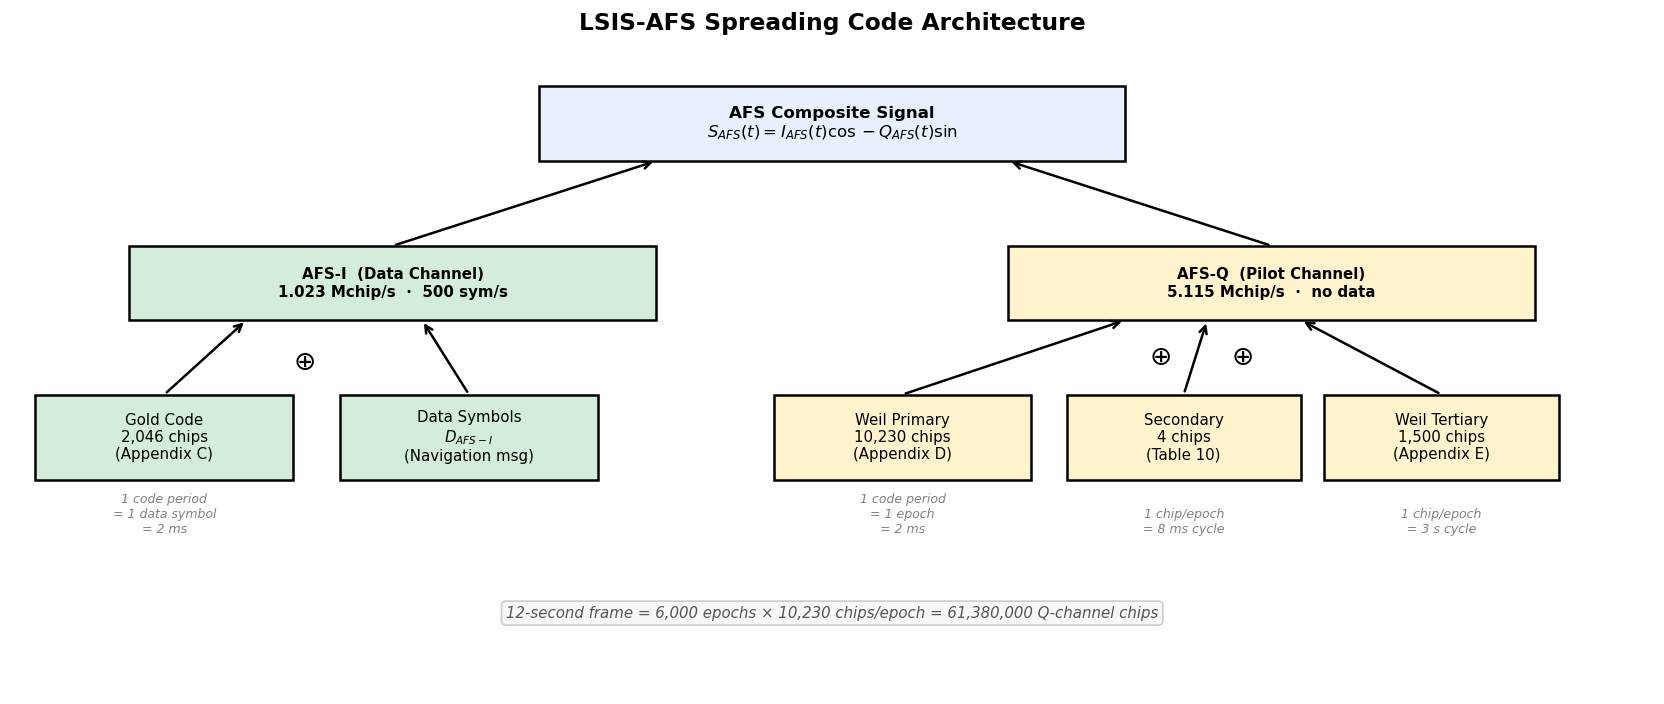

In [19]:
# --- Big-picture: AFS signal code architecture ---
# Programmatic block diagram showing the complete code hierarchy

fig, ax = plt.subplots(figsize=(14, 6))
ax.set_xlim(0, 14)
ax.set_ylim(0, 6)
ax.axis("off")
ax.set_title("LSIS-AFS Spreading Code Architecture", fontsize=14, fontweight="bold", pad=15)

def box(ax, x, y, w, h, text, color="white", ec="black", fontsize=9, bold=False):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=color, edgecolor=ec,
                                linewidth=1.5, zorder=2))
    weight = "bold" if bold else "normal"
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fontsize,
            fontweight=weight, zorder=3)

def arrow(ax, x1, y1, x2, y2, **kw):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="black", lw=1.5, **kw))

# AFS Signal header
box(ax, 4.5, 5.0, 5, 0.7, "AFS Composite Signal\n$S_{AFS}(t) = I_{AFS}(t)\\cos - Q_{AFS}(t)\\sin$",
    color="#E8F0FE", fontsize=10, bold=True)

# I channel
box(ax, 1, 3.5, 4.5, 0.7, "AFS-I  (Data Channel)\n1.023 Mchip/s  ·  500 sym/s",
    color="#D4EDDA", fontsize=9, bold=True)
arrow(ax, 3.25, 4.2, 5.5, 5.0)

# Q channel
box(ax, 8.5, 3.5, 4.5, 0.7, "AFS-Q  (Pilot Channel)\n5.115 Mchip/s  ·  no data",
    color="#FFF3CD", fontsize=9, bold=True)
arrow(ax, 10.75, 4.2, 8.5, 5.0)

# I components
box(ax, 0.2, 2.0, 2.2, 0.8, "Gold Code\n2,046 chips\n(Appendix C)", color="#D4EDDA")
box(ax, 2.8, 2.0, 2.2, 0.8, "Data Symbols\n$D_{AFS-I}$\n(Navigation msg)", color="#D4EDDA")
arrow(ax, 1.3, 2.8, 2.0, 3.5)
arrow(ax, 3.9, 2.8, 3.5, 3.5)
ax.text(2.5, 3.1, "⊕", fontsize=16, ha="center", va="center", color="black")

# Q components
box(ax, 6.5, 2.0, 2.2, 0.8, "Weil Primary\n10,230 chips\n(Appendix D)", color="#FFF3CD")
box(ax, 9.0, 2.0, 2.0, 0.8, "Secondary\n4 chips\n(Table 10)", color="#FFF3CD")
box(ax, 11.2, 2.0, 2.0, 0.8, "Weil Tertiary\n1,500 chips\n(Appendix E)", color="#FFF3CD")
arrow(ax, 7.6, 2.8, 9.5, 3.5)
arrow(ax, 10.0, 2.8, 10.2, 3.5)
arrow(ax, 12.2, 2.8, 11.0, 3.5)
ax.text(9.8, 3.15, "⊕", fontsize=16, ha="center", va="center", color="black")
ax.text(10.5, 3.15, "⊕", fontsize=16, ha="center", va="center", color="black")

# Timing labels
ax.text(1.3, 1.5, "1 code period\n= 1 data symbol\n= 2 ms", ha="center",
        fontsize=7.5, color="gray", style="italic")
ax.text(7.6, 1.5, "1 code period\n= 1 epoch\n= 2 ms", ha="center",
        fontsize=7.5, color="gray", style="italic")
ax.text(10.0, 1.5, "1 chip/epoch\n= 8 ms cycle", ha="center",
        fontsize=7.5, color="gray", style="italic")
ax.text(12.2, 1.5, "1 chip/epoch\n= 3 s cycle", ha="center",
        fontsize=7.5, color="gray", style="italic")

# Frame label
ax.text(7, 0.7, "12-second frame = 6,000 epochs × 10,230 chips/epoch = 61,380,000 Q-channel chips",
        ha="center", fontsize=9, style="italic", color="#555",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#f8f8f8", edgecolor="#ccc"))

fig.tight_layout()
plt.show()

---

## Summary

| Code family | Length | Chip rate | Channel | Purpose | Spec reference |
|-------------|--------|-----------|---------|---------|---------------|
| Gold | 2,046 | 1.023 Mchip/s | AFS-I (data) | Data spreading + ranging | §2.3.5.3.1, App. C |
| Weil primary | 10,230 | 5.115 Mchip/s | AFS-Q (pilot) | Acquisition + precise ranging | §2.3.5.3.2, App. D |
| Secondary | 4 | 1 chip/epoch | AFS-Q | Epoch disambiguation | §2.3.5.3.2, Table 10 |
| Weil tertiary | 1,500 | 1 chip/epoch | AFS-Q | Long-integration acquisition | §2.3.5.3.2, App. E |
| **Matched code** | **10,230/epoch** | **5.115 Mchip/s** | **AFS-Q** | **Combined pilot** | **§2.3.5.2** |

**Key relationships:**
- $10{,}230 = 5 \times 2{,}046$ — Weil primary is exactly 5 Gold code periods
- $6{,}000$ epochs per 12-second frame × $10{,}230$ chips/epoch = $61{,}380{,}000$ total Q-channel chips
- Tertiary code (1,500 chips) repeats 4× per frame: $1{,}500 \times 4 = 6{,}000$ epochs
- Secondary code (4 chips) repeats 1,500× per frame: $4 \times 1{,}500 = 6{,}000$ epochs

### What's next

- **[Notebook 02: Error Correction](02_error_correction.ipynb)** — BCH, LDPC, CRC, and interleaving
- **[Notebook 04: Signal Generation](04_signal_generation.ipynb)** — how these codes become I/Q samples

### API quick reference

| Function | Purpose |
|----------|---------|
| `prn_code(prn_id)` | Generate Gold code (2,046 chips) |
| `weil10230_code(prn_id)` | Generate Weil primary code (10,230 chips) |
| `weil1500_code(prn_id)` | Generate Weil tertiary code (1,500 chips) |
| `matched_code_epoch(prn_id, epoch)` | Generate assembled matched code for one epoch |
| `default_matched_assignment(prn_id)` | Look up interim code assignment (Table 11) |